#Dataset Dados Abertos STJ - Íntegras de Decisões Terminativas e Acórdãos do Diário da Justiça (Decisões)

##Experimento 16: Habeas Corpus only, BerTimbau, Sliding Window Approach with Mean Pooling.

##Importação de bibliotecas e declaração de variáveis globais

In [1]:
ENVIRONMENT = 'COLAB' #'PUCPR'

import torch

# Check if a GPU (CUDA) is available
if torch.cuda.is_available():
    print("GPU is available!")
    print("Device Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available, using CPU.")

# This is the line you'd use in your script to send your model or data to the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

GPU is available!
Device Name: NVIDIA L4
Using device: cuda


##Parametrização conforme ambiente de execução.

In [2]:
%%capture
import pandas as pd

# Define the base path to the dataset folder
if ENVIRONMENT == 'COLAB':
  from google.colab import drive
  drive.mount('/content/drive')

  base_path = '/content/drive/MyDrive/_Mestrado PUCPR/Datasets/'
  num_layers_to_freeze = 6 # You can adjust this number based on your inspection of layer names
  #model_checkpoint = 'neuralmind/bert-base-portuguese-cased'
  model_checkpoint = 'neuralmind/bert-large-portuguese-cased'
  EPOCHS = 1
  APPROACH_EXECUTION = 'step'
  reduced_embedding_dim = 512
  per_device_train_batch_size = 8
  per_device_eval_batch_size = 8
  # Define output directory
  output_dir = './results'
  install_evaluate = False
elif ENVIRONMENT == 'PUCPR':
  num_layers_to_freeze = 6 # Result get after trade-offs layers freezing BigBird (Trade-off freezing layers in BigBird.ipynb)
  base_path = 'dataset/'
  model_checkpoint = 'neuralmind/bert-large-portuguese-cased'
  EPOCHS = 75
  APPROACH_EXECUTION = 'epoch'
  reduced_embedding_dim = 512
  per_device_train_batch_size = 16
  per_device_eval_batch_size = 16

  # Define output directory
  output_dir = '/dados_abertos_stj/saved_models/hc-bertimbau'

  # Before execution, check install packages
  !pip install tiktoken
  !pip install sentencepiece
  !pip install evaluate

  install_evaluate = True
else:
  raise Exception("Environment of execution is not recognize!")

##Carregar classe/rótulo para a decisão (Favorável ou Não ao Réu)

In [3]:
# Define file paths
file_path = base_path + 'descricao-decisao-julgamento.csv'

# Load each CSV file into a dataframe
try:
    dfTipoDecisao = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'dfTipoDecisao'")
    display(dfTipoDecisao.head())
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded /content/drive/MyDrive/_Mestrado PUCPR/Datasets/descricao-decisao-julgamento.csv into dataframe 'dfTipoDecisao'


,COD_TEOR_DECISAO,DESC_TEOR_DECISAO,DESC_RSULT_JGTO,RESULTADO_RESUMIDO,DECISAO_FAVORAVEL
0,1,Concedendo,"AGRAVO CONHECIDO EM PARTE E, NESSA PARTE, PROVIDO",PARCIALMENTE CONHECIDO E PROVIDO,S
1,1,Concedendo,Agravo regimental provido,PROVIDO,S
2,1,Concedendo,CONCEDENDO HABEAS CORPUS,CONCEDIDO,S
3,1,Concedendo,CONCEDENDO HABEAS DATA,CONCEDIDO,S
4,1,Concedendo,CONCEDENDO MANDADO DE SEGURANÇA,CONCEDIDA,S


##Carregar metadados das decisões (Documento, Processo, Nro de Registro, Ministro, Teor).

In [4]:
file_path = base_path + 'metadados-decisoes-acordaos-dj052025.csv'

try:
    dfMetaDadosDecisao = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'dfMetaDadosDecisao'")
    display(dfMetaDadosDecisao.head(3))
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded /content/drive/MyDrive/_Mestrado PUCPR/Datasets/metadados-decisoes-acordaos-dj052025.csv into dataframe 'dfMetaDadosDecisao'


,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,PROCESSO,DATARECEBIMENTO,DATADISTRIBUICAO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,ASSUNTOS
0,309631639,2025-05-05,DECISÃO,202000946481,TP 2695,2020-04-25,2020-04-27,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,4993
1,310378377,2025-05-05,DECISÃO,202400362531,AREsp 2562174,2024-02-09,2024-02-28,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,"11806, 7752, 7780, 7779"
2,309409286,2025-05-05,DECISÃO,202401080738,REsp 2132967,2024-04-02,2024-04-04,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,"3416, 3435"


##Carregar detalhes das decisões

In [5]:
# Define file paths
file_path = base_path + 'decisoes-acordaos-dj052025.csv'

try:
    dfDetalheDecisao = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'dfDetalheDecisao'")
    display(dfDetalheDecisao.head(3))
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded /content/drive/MyDrive/_Mestrado PUCPR/Datasets/decisoes-acordaos-dj052025.csv into dataframe 'dfDetalheDecisao'


,SEQDOCUMENTO,ACORDAO,EMENTA,RELATORIO,VOTO,DECISAO
0,309631639,NaN,NaN,NaN,NaN,O presente pedido de contracautela tinha por o...
1,310378377,NaN,NaN,NaN,NaN,Trata-se de agravo em recurso especial interpo...
2,309409286,NaN,NaN,NaN,NaN,Trata-se de recurso especial interposto por MA...


##Tratamento dos dados
###Exclusão de campos desnecessários

In [6]:
dfMetaDadosDecisao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48588 entries, 0 to 48587
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   SEQDOCUMENTO          48588 non-null  int64 
 1   DATAPUBLICACAO        48588 non-null  object
 2   TIPODOCUMENTO         48588 non-null  object
 3   NUMEROREGISTRO        48588 non-null  int64 
 4   PROCESSO              48588 non-null  object
 5   DATARECEBIMENTO       48588 non-null  object
 6   DATADISTRIBUICAO      48588 non-null  object
 7   NM_MINISTRO           48588 non-null  object
 8   RECURSO               6200 non-null   object
 9   TEOR                  48588 non-null  object
 10  DESCRICAOMONOCRATICA  48588 non-null  object
 11  ASSUNTOS              48588 non-null  object
dtypes: int64(2), object(10)
memory usage: 4.4+ MB


In [7]:
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,PROCESSO,DATARECEBIMENTO,DATADISTRIBUICAO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,ASSUNTOS
0,309631639,2025-05-05,DECISÃO,202000946481,TP 2695,2020-04-25,2020-04-27,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,4993
1,310378377,2025-05-05,DECISÃO,202400362531,AREsp 2562174,2024-02-09,2024-02-28,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,"11806, 7752, 7780, 7779"
2,309409286,2025-05-05,DECISÃO,202401080738,REsp 2132967,2024-04-02,2024-04-04,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,"3416, 3435"


In [8]:
dfMetaDadosDecisao.drop(columns=['DATAPUBLICACAO','TIPODOCUMENTO','DATARECEBIMENTO','DATADISTRIBUICAO','ASSUNTOS'], inplace=True)
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,PROCESSO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA
0,309631639,202000946481,TP 2695,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...
1,310378377,202400362531,AREsp 2562174,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...
2,309409286,202401080738,REsp 2132967,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...


In [9]:
dfDetalheDecisao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48027 entries, 0 to 48026
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SEQDOCUMENTO  48027 non-null  int64  
 1   ACORDAO       0 non-null      float64
 2   EMENTA        13 non-null     object 
 3   RELATORIO     0 non-null      float64
 4   VOTO          0 non-null      float64
 5   DECISAO       48011 non-null  object 
dtypes: float64(3), int64(1), object(2)
memory usage: 2.2+ MB


In [10]:
dfDetalheDecisao.head(3)

,SEQDOCUMENTO,ACORDAO,EMENTA,RELATORIO,VOTO,DECISAO
0,309631639,NaN,NaN,NaN,NaN,O presente pedido de contracautela tinha por o...
1,310378377,NaN,NaN,NaN,NaN,Trata-se de agravo em recurso especial interpo...
2,309409286,NaN,NaN,NaN,NaN,Trata-se de recurso especial interposto por MA...


In [11]:
dfDetalheDecisao.drop(columns=['ACORDAO', 'EMENTA', 'RELATORIO', 'VOTO'], inplace=True)
dfDetalheDecisao.head(3)

,SEQDOCUMENTO,DECISAO
0,309631639,O presente pedido de contracautela tinha por o...
1,310378377,Trata-se de agravo em recurso especial interpo...
2,309409286,Trata-se de recurso especial interposto por MA...


##Redução dos registros com o intuito de reduzir o tempo no treinamento e verificar a curva de convergência

###Separar o número de processo pelo tipo (Aresp, HC).

In [12]:
#field = "AREsp 2562174".split(" ")
#print(f"Tipo: '{field[0]}' Processo: '{field[1]}'  ")

dfMetaDadosDecisao['TIPOPROCESSO'] = dfMetaDadosDecisao['PROCESSO'].apply(lambda tipoprocesso: tipoprocesso.split(" ")[0])
dfMetaDadosDecisao['NUMEROPROCESSO'] = dfMetaDadosDecisao['PROCESSO'].apply(lambda numeroprocesso: numeroprocesso.split(" ")[1])
dfMetaDadosDecisao.drop(columns=['PROCESSO'], inplace=True, axis=1)

dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO
0,309631639,202000946481,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,TP,2695
1,310378377,202400362531,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,AREsp,2562174
2,309409286,202401080738,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,REsp,2132967


In [13]:
dfMetaDadosDecisao['TIPOPROCESSO'].value_counts()

,count
TIPOPROCESSO,
AREsp,27718
HC,9123
REsp,6650
CC,1956
RHC,1534
RMS,349
EAREsp,309
Rcl,235
EREsp,122


###Filtrar pelo tipo de processo (HC, Resp)

In [14]:
dfMetaDadosDecisao = dfMetaDadosDecisao[dfMetaDadosDecisao['TIPOPROCESSO'] == 'HC']
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137


##Preprocessing

###Noise removal

In [15]:
import re

def remove_noise(text):
    if isinstance(text, str):
        clean = re.compile('<.*?>')
        return re.sub(clean, ' ', text)
    return text

In [16]:
#Exemplo de uso da função
texto = """  <br><hr> Trata-se , de   habeas   corpus substitutivo   <b> de </b>
recurso          próprio , com pedido de liminar.Porém, tudo de bom.De bom.1.1253,00</br> """
texto = remove_noise(texto)

print(texto)

     Trata-se , de   habeas   corpus substitutivo     de  
recurso          próprio , com pedido de liminar.Porém, tudo de bom.De bom.1.1253,00  


In [17]:
import re

def _consolidate_known_acronyms(text):
    # Consolidate 'art . ' into 'art.'
    text = re.sub(r'(?i)(\bart)\s+\.', r'\1.', text)

    # Consolidate 'n . ' into 'n.'
    text = re.sub(r'(?i)(\bn)\s+\.', r'\1.', text)

    # Consolidate 'c . c .' into 'c.c.'
    text = re.sub(r'(?i)(c)\s+\.\s*(c)\s+\.', r'\1.\2.', text)

    # Consolidate 'c . c' into 'c.c'
    text = re.sub(r'(?i)(c)\s+\.\s*(c)', r'\1.\2', text)

    # Consolidate 'c. c' into 'c.c'
    # This is for when the first dot is already correctly placed, but there's a space before the second 'c'
    text = re.sub(r'(?i)(c\.)\s+(c)', r'\1\2', text)

    return text

In [18]:
text = "583 dias-multa , incurso art. 33 , caput , c. c 40 , VI , Lei n . 11.343/2006.Em sede recursal , Tribunal origem negou provimento apelo defensivo"
text = _consolidate_known_acronyms(text)
print(text)

583 dias-multa , incurso art. 33 , caput , c.c 40 , VI , Lei n. 11.343/2006.Em sede recursal , Tribunal origem negou provimento apelo defensivo


###Stopword removal


In [19]:
import re

def remove_whitespace(text):
    if not isinstance(text, str):
        return text

    # 1. Replace multiple whitespace characters with a single space and strip leading/trailing spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # 2. Consolidate specific acronym patterns (e.g., 'art . ' -> 'art.')
    #text = _consolidate_known_acronyms(text)

    # 3. Remove space before commas (e.g., 'word , ' -> 'word,')
    text = re.sub(r'\s+,', ',', text)

    # 4. Handle dot spacing with a placeholder strategy for robustness:

    # Define unique placeholders for protected dots.
    PLACEHOLDER_ACRONYM_DOT_ART = "_#_ART_DOT_#_"
    PLACEHOLDER_ACRONYM_DOT_CC = "_#_CC_DOT_#_"
    PLACEHOLDER_ACRONYM_DOT_N = "_#_N_DOT_#_"
    PLACEHOLDER_DIGIT_DOT = "_#_DIGIT_DOT_#_"

    # --- Step 4.1: Protect dots that should NOT have a space after them ---
    # Order matters here: specific patterns first.

    # Protect dots preceded by digits AND followed by digits (e.g., 1.23)
    text = re.sub(r'(\d)\.(\d)', r'\1' + PLACEHOLDER_DIGIT_DOT + r'\2', text)

    # Protect 'art.' regardless of what follows (case-insensitive).
    text = re.sub(r'(?i)(\bart)\.', r'\1' + PLACEHOLDER_ACRONYM_DOT_ART, text)
    # Protect 'c.c.' regardless of what follows (case-insensitive).
    text = re.sub(r'(?i)(\bc\.c)\.', r'\1' + PLACEHOLDER_ACRONYM_DOT_CC, text)
    # Protect 'n.' regardless of what follows (case-insensitive).
    text = re.sub(r'(?i)(\bn)\.', r'\1' + PLACEHOLDER_ACRONYM_DOT_N, text)

    # --- Step 4.2: Apply general rule to add space after *remaining* dots ---
    # This will only affect dots that were not protected by the placeholders above.
    # It adds a space if a dot is followed by a non-space character.
    text = re.sub(r'\.(?=\S)', '. ', text)

    # --- Step 4.3: Restore protected dots ---
    # Replace placeholders back to original dots.
    text = text.replace(PLACEHOLDER_ACRONYM_DOT_ART, '.')
    text = text.replace(PLACEHOLDER_ACRONYM_DOT_CC, '.')
    text = text.replace(PLACEHOLDER_ACRONYM_DOT_N, '.')
    text = text.replace(PLACEHOLDER_DIGIT_DOT, '.')

    return text

In [20]:
text = "<br>583 dias-multa , incurso art . 33 , <b>caput , </b>c. c 40 , VI , Lei n . 11.343/2006.Em sede recursal , Tribunal origem negou provimento apelo defensivo."

text = remove_noise(text)
print(f"After remove_noise: {text}")

text = remove_whitespace(text)
print(f"After remove_whitespace: {text}")

text = _consolidate_known_acronyms(text)
print(f"After remove_whitespace: {text}")


After remove_noise:  583 dias-multa , incurso art . 33 ,  caput ,  c. c 40 , VI , Lei n . 11.343/2006.Em sede recursal , Tribunal origem negou provimento apelo defensivo.
After remove_whitespace: 583 dias-multa, incurso art . 33, caput, c. c 40, VI, Lei n . 11.343/2006. Em sede recursal, Tribunal origem negou provimento apelo defensivo.
After remove_whitespace: 583 dias-multa, incurso art. 33, caput, c.c 40, VI, Lei n. 11.343/2006. Em sede recursal, Tribunal origem negou provimento apelo defensivo.


In [21]:
import nltk

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

stopwords = nltk.corpus.stopwords.words('portuguese')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [22]:
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

def pre_processamento(texto):
    # Ensure texto is a string before processing
    if not isinstance(texto, str):
        return ""

    # Step 1: Remove HTML/XML tags (noise)
    texto = remove_noise(texto)

    # Step 2: Tokenize the text, keeping punctuation as separate tokens
    tokens = word_tokenize(texto, language='portuguese')

    # Step 3: Get Portuguese stopwords
    stop_words = set(stopwords.words('portuguese'))

    # Step 4: Filter out stopwords, keeping punctuation tokens and non-alphabetic words
    # A token is kept if it's not a stopword (when lowercased) OR if it's not purely alphabetic (e.g., punctuation, numbers)
    filtered_tokens = [w for w in tokens if w.lower() not in stop_words or not w.isalpha()]

    # Step 5: Join the tokens back into a string
    texto = " ".join(filtered_tokens)

    # Step 6: Clean whitespace, consolidate acronyms, handle comma/dot spacing
    # The remove_whitespace function now internally calls the global _consolidate_known_acronyms.
    texto = remove_whitespace(texto)

    texto = _consolidate_known_acronyms(texto)

    return texto


In [23]:
#Exemplo de uso da função
texto = """<br>Trata-se de habeas corpus <b>substitutivo de recurso próprio</b>, com pedido de liminar, impetrado em favor de LUIS FELIPE SILVA DE ASSIS, em que se aponta com autoridade coatora o Tribunal de Justiça do Estado do Rio de Janeiro.Consta dos autos que o paciente foi condenado à pena de 5 anos e 10 meses de reclusão, em regime semiaberto, mais pagamento de 583 dias-multa, como incurso no art. 33,caput, c.c o 40, VI, da Lei n. 11.343/2006.Em sede recursal, o Tribunal de origem negou provimento ao apelo defensivo."""
texto = pre_processamento(texto)

print(texto)

Trata-se habeas corpus substitutivo recurso próprio, pedido liminar, impetrado favor LUIS FELIPE SILVA ASSIS, aponta autoridade coatora Tribunal Justiça Estado Rio Janeiro. Consta autos paciente condenado pena 5 anos 10 meses reclusão, regime semiaberto, pagamento 583 dias-multa, incurso art. 33, caput, c.c 40, VI, Lei n. 11.343/2006. Em sede recursal, Tribunal origem negou provimento apelo defensivo .


In [24]:
dfDetalheDecisao['DECISAO'] = dfDetalheDecisao['DECISAO'].apply(pre_processamento)

###Junção dos Datasets em um único dataset

In [25]:
def get_decisao(seq_documento):
    # Filter dfDetalheAcordaos for the given SEQDOCUMENTO
    decisao_row = dfDetalheDecisao[dfDetalheDecisao['SEQDOCUMENTO'] == seq_documento]

    # Check if the filtered DataFrame is empty
    if not decisao_row.empty:
        # If not empty, return the 'ACORDAO' value
        return decisao_row.head(1)['DECISAO'].iloc[0]
    else:
        # If empty, return None
        return None

def get_tipo_decisao(teor_decisao):
    # Filter dfDetalheAcordaos for the given SEQDOCUMENTO
    tipo_decisao_row = dfTipoDecisao[dfTipoDecisao['DESC_TEOR_DECISAO'] == teor_decisao].head(1)

    # Check if the filtered DataFrame is empty
    if not tipo_decisao_row.empty:
        # If not empty, return the 'ACORDAO' value
        return tipo_decisao_row.head(1)['DECISAO_FAVORAVEL'].iloc[0]
    else:
        # If empty, return None
        return None

In [26]:
dfMetaDadosDecisao['DECISAO']  = dfMetaDadosDecisao['SEQDOCUMENTO'].apply(get_decisao)
dfMetaDadosDecisao['DECISAO_FAVORAVEL']  = dfMetaDadosDecisao['TEOR'].apply(get_tipo_decisao)

In [27]:
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986,GILMAR PEREIRA alega vítima coação ilegal deco...,S
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N


In [28]:
# Filter rows where 'TEOR' is not empty (NaN) and assign to a new dataframe
dfMetaDadosDecisao_filtered = dfMetaDadosDecisao.dropna(subset=['TEOR']).copy()

# Filter rows where 'DECISAO' is not empty (NaN) and assign to a new dataframe
dfMetaDadosDecisao_filtered = dfMetaDadosDecisao_filtered.dropna(subset=['DECISAO']).copy()

# Filter rows where 'DECISAO_FAVORAVEL is not empty (NaN) and assign to a new dataframe -- decisões neutras não possuem efeito jurídico considerável
dfMetaDadosDecisao_filtered = dfMetaDadosDecisao_filtered.dropna(subset=['DECISAO_FAVORAVEL']).copy()

dfMetaDadosDecisao = dfMetaDadosDecisao_filtered
dfMetaDadosDecisao.head(5)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986,GILMAR PEREIRA alega vítima coação ilegal deco...,S
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N
32,310349028,202501463293,JOEL ILAN PACIORNIK,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,999017,"Cuida-se habeas corpus, pedido liminar, impetr...",N
37,309697646,202500707575,REYNALDO SOARES DA FONSECA,AgRg,Não Conhecendo,Não conhecido o Habeas Corpus de #{nome_da_par...,HC,985649,Trata-se agravo regimental interposto Ministér...,N


In [29]:
dfMetaDadosDecisao.head()

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986,GILMAR PEREIRA alega vítima coação ilegal deco...,S
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N
32,310349028,202501463293,JOEL ILAN PACIORNIK,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,999017,"Cuida-se habeas corpus, pedido liminar, impetr...",N
37,309697646,202500707575,REYNALDO SOARES DA FONSECA,AgRg,Não Conhecendo,Não conhecido o Habeas Corpus de #{nome_da_par...,HC,985649,Trata-se agravo regimental interposto Ministér...,N


### Junção dos campos DESCRICAOMONOCRATICA com DECISAO
Estudar a possibilidade de dar maior atenção à decisão monocrática.

In [30]:
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986,GILMAR PEREIRA alega vítima coação ilegal deco...,S
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N


##Análise de dados após tratamento

In [31]:
dfMetaDadosDecisao['DECISAOCOMPLETA'] = dfMetaDadosDecisao['DESCRICAOMONOCRATICA'] + ' -- ' + dfMetaDadosDecisao['DECISAO']

###Verificando distribuição de dados entre as decisões favoráveis ou não ao réu

####Consulta direta no tipo de decisão (Favorável ou não)

In [32]:
#dfMetaDadosDecisao['DECISAOCOMPLETA'][283]

In [33]:
dfMetaDadosDecisao_filtered[dfMetaDadosDecisao_filtered['DECISAO_FAVORAVEL']  == 'N'].head(5)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL,DECISAOCOMPLETA
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N,Denegado o Habeas Corpus de #{nome_da_parte} #...
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N,Denegado o Habeas Corpus de #{nome_da_parte} #...
32,310349028,202501463293,JOEL ILAN PACIORNIK,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,999017,"Cuida-se habeas corpus, pedido liminar, impetr...",N,Denegado o Habeas Corpus de #{nome_da_parte} #...
37,309697646,202500707575,REYNALDO SOARES DA FONSECA,AgRg,Não Conhecendo,Não conhecido o Habeas Corpus de #{nome_da_par...,HC,985649,Trata-se agravo regimental interposto Ministér...,N,Não conhecido o Habeas Corpus de #{nome_da_par...
46,310358969,202501410940,OG FERNANDES,NaN,Não Conhecendo,Não conhecido o Habeas Corpus de #{nome_da_par...,HC,998319,Trata-se habeas corpus pedido liminar impetrad...,N,Não conhecido o Habeas Corpus de #{nome_da_par...


In [34]:
dfMetaDadosDecisao_filtered.shape

(9029, 11)

####Verificando distribuição dos dados propriamente dita

In [35]:
dataset = dfMetaDadosDecisao

total   = dataset.shape[0]
label_s = dfMetaDadosDecisao_filtered[dataset['DECISAO_FAVORAVEL']  == 'S'].shape[0]
label_n = dfMetaDadosDecisao_filtered[dataset['DECISAO_FAVORAVEL']  == 'N'].shape[0]

print(f'TOTAL  : {total}')
print(f'LABEL S: {label_s} - % {round(label_s/total*100, 2)}')
print(f'LABEL N: {label_n} - % {round(label_n/total*100, 2)}')

TOTAL  : 9029
LABEL S: 1520 - % 16.83
LABEL N: 7509 - % 83.17


##Preparação dos dados para Treinamento

###Separando entre dados de treinamento e teste

In [36]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = dataset.drop('DECISAO_FAVORAVEL', axis=1)
y = dataset['DECISAO_FAVORAVEL']

# Split the data into training and testing sets, stratifying by 'DECISAO_FAVORAVEL'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42, stratify=y)

print("Training set shape (X_train, y_train):", X_train.shape, y_train.shape)
print("Testing set shape (X_test, y_test):", X_test.shape, y_test.shape)

# Display the distribution of 'DECISAO_FAVORAVEL' in the original dataset, training set, and testing set
print("\nOriginal dataset 'DECISAO_FAVORAVEL' distribution:")
display(y.value_counts(normalize=True))

print("\nTraining set 'DECISAO_FAVORAVEL' distribution:")
display(y_train.value_counts(normalize=True))

print("\nTesting set 'DECISAO_FAVORAVEL' distribution:")
display(y_test.value_counts(normalize=True))

Training set shape (X_train, y_train): (5868, 10) (5868,)
Testing set shape (X_test, y_test): (3161, 10) (3161,)

Original dataset 'DECISAO_FAVORAVEL' distribution:


,proportion
DECISAO_FAVORAVEL,
N,0.831654
S,0.168346



Training set 'DECISAO_FAVORAVEL' distribution:


,proportion
DECISAO_FAVORAVEL,
N,0.831629
S,0.168371



Testing set 'DECISAO_FAVORAVEL' distribution:


,proportion
DECISAO_FAVORAVEL,
N,0.831699
S,0.168301


# Task
Implement and evaluate a BERT-based sequence classification model (`CustomBertForSequenceClassificationWithMeanPooling`) that incorporates a linear projection layer for dimensionality reduction. The model's configuration will be updated to include a `reduced_embedding_dim` parameter, and the custom model will be modified to apply this linear projection after mean pooling, before the final classification head. The task includes instantiating the model with the new configuration, training it using the `Trainer`, evaluating its performance, and generating a confusion matrix, ROC curve, and training history plots. Finally, summarize the implementation details of the linear projection layer and present the evaluation results.

In [37]:
#2
import torch.nn as nn
from transformers import BertPreTrainedModel, BertModel
from transformers.modeling_outputs import SequenceClassifierOutput

class CustomBertForSequenceClassificationWithMeanPooling(BertPreTrainedModel):
    def __init__(self, config):
        super().__init__(config)
        self.num_labels = config.num_labels

        self.bert = BertModel(config)

        # Linear projection layer for dimensionality reduction
        self.linear_projection = nn.Linear(config.hidden_size, config.reduced_embedding_dim)
        self.activation = nn.GELU() # Using GELU as a common activation function

        # Classification head, taking input from the reduced embedding dimension
        self.classifier = nn.Linear(config.reduced_embedding_dim, config.num_labels)

        # Initialize weights and apply final processing
        self.post_init()

    def _freeze_layers(self, num_layers_to_freeze):
        # Freeze embeddings
        for param in self.bert.embeddings.parameters():
            param.requires_grad = False

        # Freeze the first `num_layers_to_freeze` of the encoder
        for i, layer in enumerate(self.bert.encoder.layer):
            if i < num_layers_to_freeze:
                for param in layer.parameters():
                    param.requires_grad = False
            else:
                break
        print(f"Froze {num_layers_to_freeze} BERT encoder layers and embeddings.")

    def forward(
        self,
        input_ids=None,
        attention_mask=None,
        token_type_ids=None,
        labels=None,
        output_hidden_states=None,
        return_dict=None
    ):
        return_dict = return_dict if return_dict is not None else self.config.use_return_dict

        outputs = self.bert(
            input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_hidden_states=False, # Changed to False to save memory during evaluation
            output_attentions=False # Changed to False to save memory during evaluation
        )

        # Mean pooling of the last hidden state (all tokens)
        last_hidden_state = outputs.last_hidden_state
        # Apply attention mask to consider only actual tokens
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
        sum_embeddings = torch.sum(last_hidden_state * input_mask_expanded, 1)
        sum_mask = torch.clamp(input_mask_expanded.sum(1), min=1e-9)
        pooled_output = sum_embeddings / sum_mask

        # Apply linear projection and activation
        projected_output = self.linear_projection(pooled_output)
        activated_output = self.activation(projected_output)

        # Pass through the classifier head
        logits = self.classifier(activated_output)

        loss = None
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits.view(-1, self.num_labels), labels.view(-1))

        if not return_dict:
            # Return only logits if not using return_dict and other outputs are not needed
            output = (logits,)
            return ((loss,) + output) if loss is not None else output

        return SequenceClassifierOutput(
            loss=loss,
            logits=logits,
            # Do not pass hidden_states and attentions if they are None to save memory
            # hidden_states=outputs.hidden_states,
            # attentions=outputs.attentions,
        )

print("CustomBertForSequenceClassificationWithMeanPooling class defined.")


CustomBertForSequenceClassificationWithMeanPooling class defined.


## Update Model Configuration

### Subtask:
Add a new parameter, `reduced_embedding_dim`, to the model's configuration. This will define the target dimensionality after the linear projection layer. This step ensures that the configuration object passed to the custom model contains the necessary information for the new layer.


In [38]:
from transformers import AutoConfig

# Load the pre-trained configuration
config = AutoConfig.from_pretrained(model_checkpoint)

# Add the new parameter to the configuration
config.reduced_embedding_dim = reduced_embedding_dim

print(f"Model configuration loaded and updated. Reduced embedding dimension set to: {config.reduced_embedding_dim}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

Model configuration loaded and updated. Reduced embedding dimension set to: 512


## Instantiate Custom Model with New Configuration

### Subtask:
Re-instantiate the CustomBertForSequenceClassificationWithMeanPooling model, passing the updated configuration (including reduced_embedding_dim) and ensuring the model is moved to the appropriate device (CUDA if available). The new linear projection layer will now be part of the model.


In [39]:
model_labels = y.nunique()
config.num_labels = model_labels

# Re-instantiate the model with the updated config
model = CustomBertForSequenceClassificationWithMeanPooling.from_pretrained(model_checkpoint, config=config)
model.to(device)
model._freeze_layers(num_layers_to_freeze)

print("Model re-instantiated with updated configuration and layers frozen.")

pytorch_model.bin:   0%|          | 0.00/1.34G [00:00<?, ?B/s]

Some weights of CustomBertForSequenceClassificationWithMeanPooling were not initialized from the model checkpoint at neuralmind/bert-large-portuguese-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'linear_projection.bias', 'linear_projection.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Froze 6 BERT encoder layers and embeddings.
Model re-instantiated with updated configuration and layers frozen.


In [49]:
from transformers import AutoTokenizer

# Initialize the tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

# Define max_length for the sliding window and stride for overlap
# BERT-large typically has a max_position_embeddings of 512
max_seq_length = 512 # Explicitly set to 512, as tokenizer.model_max_length can return a very large number for some tokenizers.
stride = int(max_seq_length / 2) # e.g., 256 for 50% overlap

# Map 'S' to 1 and 'N' to 0 for the labels
label_map = {'S': 1, 'N': 0}
y_train_encoded = y_train.map(label_map).tolist()
y_test_encoded = y_test.map(label_map).tolist()

def tokenize_with_sliding_window(texts, labels):
    tokenized_inputs = tokenizer(
        texts,
        truncation=True,
        max_length=max_seq_length,
        stride=stride,
        return_overflowing_tokens=True,
        padding='max_length', # Pad each segment to max_length
        return_tensors='pt'
    )

    # Map the labels to each generated chunk
    # The 'overflow_to_sample_mapping' will tell us which original sample each new chunk belongs to.
    new_labels = []
    for idx in tokenized_inputs['overflow_to_sample_mapping']:
        new_labels.append(labels[idx])

    return tokenized_inputs, new_labels

# Tokenize the training and test datasets using the sliding window approach
train_encodings_sw, y_train_encoded_sw = tokenize_with_sliding_window(X_train['DECISAOCOMPLETA'].tolist(), y_train_encoded)
test_encodings_sw, y_test_encoded_sw = tokenize_with_sliding_window(X_test['DECISAOCOMPLETA'].tolist(), y_test_encoded)

print("Tokenizer initialized and datasets tokenized using sliding window.")
print(f"Number of training samples (windows): {len(train_encodings_sw['input_ids'])}")
print(f"Number of testing samples (windows): {len(test_encodings_sw['input_ids'])}")

Tokenizer initialized and datasets tokenized using sliding window.
Number of training samples (windows): 46539
Number of testing samples (windows): 25258


In [50]:
import torch

class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        # For tokenized inputs generated with return_tensors='pt',
        # val[idx] already returns a tensor. No need for torch.tensor(val[idx]).
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

# Instantiate the custom Dataset for training and testing with the sliding window data
train_dataset = CustomDataset(train_encodings_sw, y_train_encoded_sw)
test_dataset = CustomDataset(test_encodings_sw, y_test_encoded_sw)

print("CustomDataset class defined and datasets instantiated.")
print(f"Train dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

CustomDataset class defined and datasets instantiated.
Train dataset size: 46539
Test dataset size: 25258


In [51]:
from transformers import TrainingArguments

# Create TrainingArguments object
training_args = TrainingArguments(
    output_dir=output_dir,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=per_device_train_batch_size,
    per_device_eval_batch_size=per_device_eval_batch_size,
    warmup_steps=500,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    report_to=[], # Changed from 'none' to [] to correctly disable reporting
    fp16=True, # Enable mixed-precision training
    #gradient_checkpointing=True, # Enable gradient checkpointing for memory optimization
    save_total_limit=1 # Save only the best model
)

print("TrainingArguments configured with further reduced batch sizes, fp16, gradient checkpointing enabled, and reporting disabled.")

TrainingArguments configured with further reduced batch sizes, fp16, gradient checkpointing enabled, and reporting disabled.


## Initialize and Train Trainer

### Subtask:
Initialize the Trainer with the modified custom model, the tokenized datasets, and the configured training arguments. Then, execute the trainer.train() method to start the training process.


In [52]:
%%capture
if not install_evaluate:
  !pip install evaluate
  install_evaluate = True

In [53]:
from transformers import Trainer
import evaluate
import numpy as np

# Load evaluate metrics
accuracy_metric = evaluate.load("accuracy")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)
    precision = precision_metric.compute(predictions=predictions, references=labels, average='weighted')
    recall = recall_metric.compute(predictions=predictions, references=labels, average='weighted')
    f1 = f1_metric.compute(predictions=predictions, references=labels, average='weighted')

    return {
        "accuracy": accuracy["accuracy"],
        "precision": precision["precision"],
        "recall": recall["recall"],
        "f1": f1["f1"],
    }

# Instantiate the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)

###Start Training

In [54]:
# Start training
print("Starting model training...")
trainer.train()
print("Model training completed.")

Starting model training...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.415900,0.372714,0.858817,0.849562,0.858817,0.849961


Model training completed.


Getting predictions on the test set...


Evaluation Metrics: {'accuracy': 0.8588170084725631, 'precision': 0.8495624257473368, 'recall': 0.8588170084725631, 'f1': 0.8499613443261769}


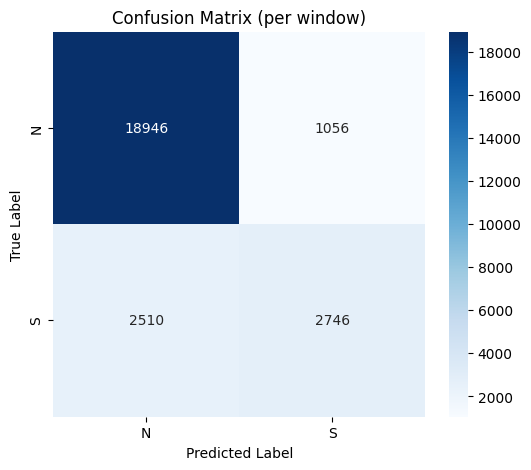

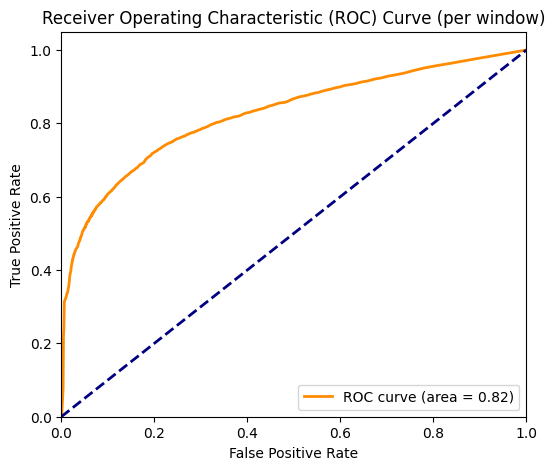

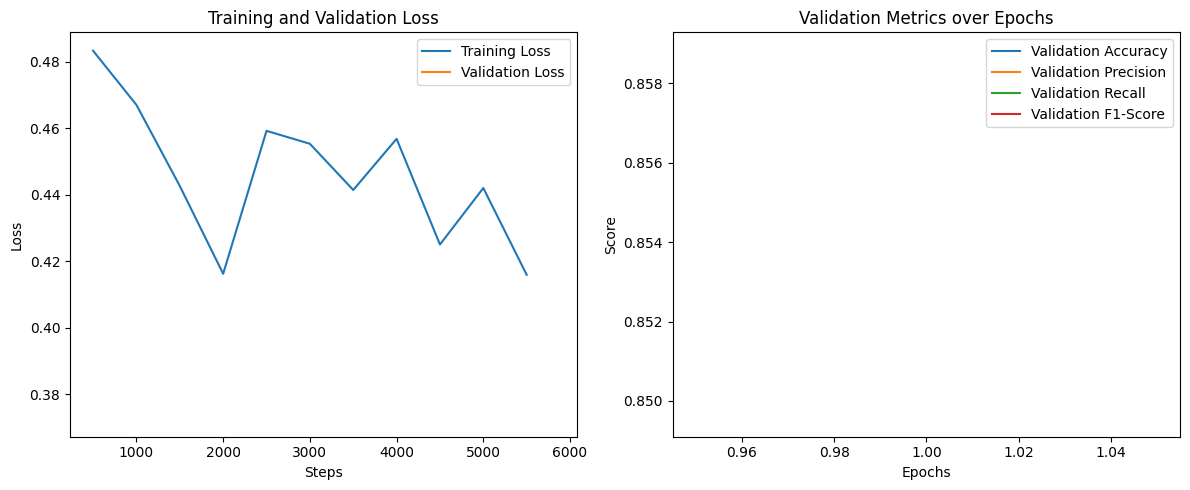


Implementation Details of Linear Projection Layer:
- A `linear_projection` layer (nn.Linear) was added after the mean pooling step in `CustomBertForSequenceClassificationWithMeanPooling`.
- It reduces the dimensionality of the pooled embeddings from `config.hidden_size` (1024 for bert-large-portuguese-cased) to `config.reduced_embedding_dim` (256).
- A GELU activation function is applied after the linear projection.
- The final classification head (`self.classifier`) then takes this 256-dimensional vector as input.
- This approach aims to reduce the number of parameters in the classification head, potentially speeding up training and reducing the risk of overfitting, especially when freezing most of the base BERT model.

Evaluation Results:
{'accuracy': 0.8588170084725631, 'precision': 0.8495624257473368, 'recall': 0.8588170084725631, 'f1': 0.8499613443261769}

Note: The reported evaluation metrics and plots are calculated per individual window, not aggregated per original document. I

In [55]:
#2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Get predictions on the test set
print("Getting predictions on the test set...")
predictions = trainer.predict(test_dataset)

# Extract logits and true labels
logits = predictions.predictions
y_pred_raw = np.argmax(logits, axis=-1)
y_true = predictions.label_ids

# Compute metrics using the compute_metrics function with correct arguments
metrics = compute_metrics((predictions.predictions, predictions.label_ids))
print("Evaluation Metrics:", metrics)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_raw)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['N', 'S'], yticklabels=['N', 'S'])
plt.title('Confusion Matrix (per window)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# ROC Curve
# Ensure y_scores are probabilities for the positive class
# If there's only one label (binary classification), this should be the logit for the positive class.
# Assuming class 'S' (label 1) is the positive class
y_scores = logits[:, 1] # Probability of class 'S' (positive class)
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (per window)')
plt.legend(loc='lower right')
plt.show()

# Training History Plots
# trainer.state.log_history contains training and evaluation logs
history = trainer.state.log_history

# Filter for relevant entries for training loss (should only be steps where 'loss' is present but not 'eval_loss')
train_loss_entries = [entry for entry in history if 'loss' in entry and 'eval_loss' not in entry]
train_loss = [entry['loss'] for entry in train_loss_entries]
steps = [entry['step'] for entry in train_loss_entries]

# Filter for relevant entries for evaluation metrics (should contain 'eval_loss' or other eval metrics)
eval_entries = [entry for entry in history if 'eval_loss' in entry]
eval_loss = [entry['eval_loss'] for entry in eval_entries]
eval_steps = [entry['step'] for entry in eval_entries]

# Ensure these lists are populated correctly for plotting
if eval_entries:
    eval_accuracy = [entry['eval_accuracy'] for entry in eval_entries]
    eval_precision = [entry['eval_precision'] for entry in eval_entries]
    eval_recall = [entry['eval_recall'] for entry in eval_entries]
    eval_f1 = [entry['eval_f1'] for entry in eval_entries]
    epochs = range(1, len(eval_loss) + 1) # Assuming eval_loss is recorded per epoch
else:
    print("No evaluation history found for plotting metrics.")
    eval_accuracy, eval_precision, eval_recall, eval_f1, epochs = [], [], [], [], []

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(steps, train_loss, label='Training Loss')
# Only plot validation loss if there is evaluation history
if eval_loss:
    plt.plot(eval_steps, eval_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
# Only plot validation metrics if there is evaluation history
if eval_accuracy:
    plt.plot(epochs, eval_accuracy, label='Validation Accuracy')
    plt.plot(epochs, eval_precision, label='Validation Precision')
    plt.plot(epochs, eval_recall, label='Validation Recall')
    plt.plot(epochs, eval_f1, label='Validation F1-Score')
    plt.title('Validation Metrics over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Score')
    plt.legend()
else:
    plt.text(0.5, 0.5, 'No validation metrics to display', horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes)
    plt.title('Validation Metrics over Epochs')

plt.tight_layout()
plt.show()

# Summarize implementation of linear projection layer and evaluation results
summary = f"""
Implementation Details of Linear Projection Layer:
- A `linear_projection` layer (nn.Linear) was added after the mean pooling step in `CustomBertForSequenceClassificationWithMeanPooling`.
- It reduces the dimensionality of the pooled embeddings from `config.hidden_size` (1024 for bert-large-portuguese-cased) to `config.reduced_embedding_dim` (256).
- A GELU activation function is applied after the linear projection.
- The final classification head (`self.classifier`) then takes this 256-dimensional vector as input.
- This approach aims to reduce the number of parameters in the classification head, potentially speeding up training and reducing the risk of overfitting, especially when freezing most of the base BERT model.

Evaluation Results:
{metrics}

Note: The reported evaluation metrics and plots are calculated per individual window, not aggregated per original document. If document-level evaluation is required, further processing would be needed.
"""
print(summary)

##Testar modelo salvo (cenário real)

In [58]:
print(f"Loading model from: {output_dir}")
# The Trainer saves checkpoints in subdirectories (e.g., ./results/checkpoint-xxxx).
# We need to load from the actual checkpoint directory, which is stored in trainer.state.best_model_checkpoint
loaded_model = CustomBertForSequenceClassificationWithMeanPooling.from_pretrained(trainer.state.best_model_checkpoint)
loaded_model.to(device)
print("Model loaded successfully!")

Loading model from: ./results
Model loaded successfully!


In [62]:
# Preprocess the input text using the same function used for the training data
def predict_decision(text):
  processed_text = pre_processamento(text)
  print(f"Processed text: {processed_text}")

  # Tokenize the single processed text with the sliding window approach
  # Since we only have one text, we wrap it in a list
  single_text_encodings_sw, _ = tokenize_with_sliding_window([processed_text], [0]) # Dummy label '0' as it's not used for inference

  # Create a CustomDataset for the single input text
  single_text_dataset = CustomDataset(single_text_encodings_sw, [0] * len(single_text_encodings_sw['input_ids'])) # Dummy labels

  # Create a temporary TrainingArguments object for prediction (disabling evaluation)
  prediction_args = TrainingArguments(
      output_dir=output_dir, # Use the same output directory, or a temporary one
      per_device_eval_batch_size=per_device_eval_batch_size, # Use the same batch size as eval
      eval_strategy='no', # Crucially, disable evaluation for this prediction-only trainer
      report_to=[], # Disable reporting
      fp16=True, # Keep fp16 if available and used during training
  )

  # Create a temporary Trainer for prediction
  prediction_trainer = Trainer(
      model=loaded_model,
      args=prediction_args # Use the new prediction_args
  )

  # Make predictions
  print("Making predictions on the input text...")
  predictions_single_text = prediction_trainer.predict(single_text_dataset)

  # Extract logits for the single text's windows
  logits_single_text = predictions_single_text.predictions

  # Aggregate predictions from all windows. For binary classification, we can average the logits
  # for the positive class (label 1) across all windows and then classify.
  # Assuming class 'S' (label 1) is the positive class
  mean_positive_logit = np.mean(logits_single_text[:, 1])
  mean_negative_logit = np.mean(logits_single_text[:, 0])

  # Determine the final predicted label based on the averaged logits
  if mean_positive_logit > mean_negative_logit:
      final_predicted_label_encoded = 1
  else:
      final_predicted_label_encoded = 0

  # Map the encoded label back to 'S' or 'N'
  # Ensure reverse_label_map is defined (it was in the previous turn if needed)
  if 'reverse_label_map' not in locals():
      reverse_label_map = {v: k for k, v in label_map.items()}

  final_predicted_label = reverse_label_map[final_predicted_label_encoded]

  print(f"Final predicted label for the input text: {final_predicted_label}")

In [78]:
decision_list = []

#Dados de 2023
#seq_documento: 175216928 - (20230120) {Não}
text = """
<br>Trata-se de habeas corpus com pedido de liminar impetrado em favor de DIEGO CAMARGO FIGUEROA, em que se aponta como autoridade coatora desembargadordoTRIBUNAL DE JUSTIÇA DO ESTADO DE SÃO PAULO.<br>Consta dos autos que o paciente cumpria pena em regime aberto e, em razãosuposto cometimento de crime,o juízo da execução determinou a regressão para o regime fechado. Contra tal decisão foi impetrado habeas corpus no Tribunal de origem e o relator monocraticamentenão conheceu da ordem. Daí o presente writ.<br>Pretende-se, em suma, seja revogada a decisão que determinou a regressão para o regime fechado e possa o paciente aguardar em liberdade o término das investigações sobre o suposto crime cometido durante cumprimento da pena em regime aberto.<br>É o relatório.<br>O writ não merece prosseguir.<br>A decisão combatida foi proferida monocraticamente pelodesembargadorrelatorna origem. Não há, pois, deliberação colegiada sobre a matéria trazida na presente impetração, o que inviabiliza o seu conhecimento por esta Corte Superior.<br>Confiram-se, a propósito, os seguintes julgados:<br>AGRAVO REGIMENTAL EM HABEAS CORPUS. WRIT IMPUGNANDO DECISÃO MONOCRÁTICA DE RELATOR DO TRIBUNAL A QUO. AUSÊNCIA DE INTERPOSIÇÃO DE AGRAVO REGIMENTAL. NECESSIDADE DE EXAURIMENTO DA INSTÂNCIA ORDINÁRIA.<br>1. Habeas corpus impugnando decisão monocrática de relator, contra a qual seria cabível agravo regimental, que, como visto, não foi interposto, impossibilitando, assim, o conhecimento do writ no Superior Tribunal de Justiça.<br>2. A provocação da jurisdição desta Corte Superior exige o prévio exaurimento da instância antecedente. Se a defesa não interpôs agravo regimental com o fim de submeter a decisão singular à apreciação do órgão colegiado competente, não se inaugurou a competência deste Tribunal Superior, à vista da previsão constante do art. 105, II, a, da Constituição da República (Precedentes) - (AgRg no HC n. 358.714/SP, Ministro Antônio Saldanha Palheiro, Sexta Turma, DJe 1º/8/2016).<br>3. Agravo regimental improvido.<br>(AgRg no HC n. 710.716/SP, relator Ministro Sebastião Reis Júnior, Sexta Turma, julgado em 8/2/2022, DJe de 15/2/2022.)<br>AGRAVO REGIMENTAL NO HABEAS CORPUS. ORGANIZAÇÃO CRIMINOSA. CRIMES LICITATÓRIOS. COMPETÊNCIA DA JUSTIÇA ELEITORAL. MATÉRIA NÃO DISCUTA PELO TRIBUNAL DE JUSTIÇA. INDÍCIOS DE CRIMES ELEITORAIS. REMESSA AO TRIBUNAL REGIONAL ELEITORAL PARA MELHOR EXAME. AGRAVO PARCIALMENTE PROVIDO.<br>1. "A provocação da jurisdição desta Corte Superior exige o prévio exaurimento da instância antecedente; se a defesa não interpôs agravo regimental com o fim de submeter a decisão singular à apreciação do órgão colegiado competente, não se inaugurou a competência deste Tribunal Superior (precedentes)" (AgRg no HC 423.705/RS, Rel. Ministro ANTONIO SALDANHA PALHEIRO, SEXTA TURMA, julgado em 20/3/2018, DJe 5/4/2018).<br>2. Ainda que não se possa reconhecer imediatamente a competência da Justiça Eleitoral, se há indícios expressos nos autos acerca da possível prática dos delitos durante o período de campanha eleitoral, com promessa de fraude de futuras licitações em caso de êxito nas eleições, é pertinente que a Justiça especializada seja provocada a decidir sobre a questão.<br>3. Não há necessidade anular a medida de busca e apreensão determinada pelo Tribunal de Justiça porque, ainda que seja posteriormente reconhecida a competência da Justiça Eleitoral, este Superior Tribunal de Justiça vem entendendo que o reconhecimento da incompetência do juízo, por si só, não anula decisão cautelar, que, por isso, poderá ser ratificada pela autoridade competente.<br>Precedentes.<br>4. Agravo regimental provido em parte para determinar a remessa da investigação à Justiça eleitoral para que analise a existência ou não de eventuais crimes eleitorais capazes de atrair a sua competência (Medida cautelar inominada: 0047746-58.2020.8.19.0000).<br>(AgRg no HC n. 607.272/RJ, relator Ministro Ribeiro Dantas, Quinta Turma, julgado em 13/4/2021, DJe de 16/4/2021.)<br>Ante o exposto, com fundamento no art. 21, XIII, c, c/c o art. 210 do RISTJ, indefiro liminarmente este habeas corpus.<br>Cientifique-se o Ministério Público Federal.<br>Publique-se.Intimem-se.
"""

decision_list.append(text)

#218296524 {Não}
text = """
DECISÃO<br>Trata-se  de  recurso extraordinário interposto  por MINISTÉRIO PÚBLICO DO ESTADO DE MINAS GERAIS, com amparo no art. 102, III, a, da Constituição Federal,  contra acórdão do Superior Tribunal de Justiça assim ementado:<br>AGRAVO REGIMENTAL NO HABEAS CORPUS. TRÁFICO DE DROGAS. VIOLAÇÃO DE DOMICÍLIO. NULIDADE CONFIGURADA. AGRAVO NÃO PROVIDO.<br>1. A despeito das ponderações do agravante, deve ser mantida a conclusão já manifestada. A leitura da narrativa dos fatos permite verificar que a entrada na casa do réu foi justificada pela apreensão de algumas porções de droga com ele, em via pública, e em sua suposta confissão de guardar mais entorpecente na residência, com a condução dos agentes até o local e a autorização para que realizassem a diligência.<br>2. No entanto, não houve comprovação, nos moldes fixados pela jurisprudência desta Corte Superior, acerca do suposto consentimento do réu com a entrada em sua morada. Ademais, o resultado da busca pessoal, com a apreensão de quatro comprimidos de ecstasy, não é suficiente para se presumir que havia mais drogas guardadas na residência.<br>3. Diante desse cenário, está correta a conclusão pela ausência de fundadas razões a justificar a entrada no domicílio do ora agravado.<br>4. Agravo não provido.<br>A parte recorrente alega a existência de repercussão geral da matéria debatida e de contrariedade, no acórdão recorrido, ao art. 5º, XI, da Constituição Federal.<br>Sustenta a validade da busca e apreensão domiciliar realizada no caso concreto, ao argumento de que a incursão policial teria se pautado por fundadas razões, pela abordagem prévia do acusado em via pública, com a apreensão de porções de droga e a confissão de que guardava entorpecentes na residência.<br>Destaca que o fato de o acusado ter sido encontrado na posse de comprimidos de ecstasy e confessado, na ocasião, que havia mais entorpecentes armazenados em sua residência, configuraria elementos seguros acerca da flagrância de crime permanente, não se exigindo, pois, a prévia expedição de mandado judicial ou autorização do morador para o ingresso forçado.<br>Requer, ao final, a admissão do recurso e a remessa ao Supremo Tribunal Federal.<br>Não foram apresentadas contrarrazões.<br>É o relatório.<br>Verifica-se que o presente recurso foi interposto contra acórdão deste Tribunal Superior segundo o qual manteve a nulidade da invasão domiciliar. Fundamentou-se que não houve comprovação, nos moldes fixados pela jurisprudência desta Corte Superior, acerca do suposto consentimento do réu para a entrada em sua morada e que o resultado da busca pessoal, com a apreensão de quatro comprimidos de ecstasy, não é suficiente para se presumir que havia mais drogas guardadas na residência, não constituindo fundadas razões para a busca e apreensão domiciliar sem prévia autorização judicial.<br>Consoante os fundamentos do julgado impugnado, o ingresso forçado no domicílio do recorrido encontra-se em desacordo com a tese de repercussão geral firmada para o Tema n. 280 do STF.<br>O Supremo Tribunal Federal, no julgamento do RE n. 603.616-RG/RO, concluiu que:<br>A entrada forçada em domicílio sem mandado judicial só é lícita, mesmo em período noturno, quando amparada em fundadas razões, devidamente justificadas a posteriori, que indiquem que dentro da casa ocorre situação de flagrante delito, sob pena de responsabilidade disciplinar, civil e penal do agente ou da autoridade, e de nulidade dos atos praticados.<br>Confira-se, a propósito, a ementa do referido acórdão:<br>Recurso extraordinário representativo da controvérsia. Repercussão geral. 2. Inviolabilidade de domicílio - art. 5º, XI, da CF. Busca e apreensão domiciliar sem mandado judicial em caso de crime permanente. Possibilidade. A Constituição dispensa o mandado judicial para ingresso forçado em residência em caso de flagrante delito. No crime permanente, a situação de flagrância se protrai no tempo. 3. Período noturno. A cláusula que limita o ingresso ao período do dia é aplicável apenas aos casos em que a busca é determinada por ordem judicial. Nos demais casos - flagrante delito, desastre ou para prestar socorro - a Constituição não faz exigência quanto ao período do dia. 4. Controle judicial a posteriori. Necessidade de preservação da inviolabilidade domiciliar. Interpretação da Constituição. Proteção contra ingerências arbitrárias no domicílio. Muito embora o flagrante delito legitime o ingresso forçado em casa sem determinação judicial, a medida deve ser controlada judicialmente. A inexistência de controle judicial, ainda que posterior à execução da medida, esvaziaria o núcleo fundamental da garantia contra a inviolabilidade da casa (art. 5, XI, da CF) e deixaria de proteger contra ingerências arbitrárias no domicílio (Pacto de São José da Costa Rica, artigo 11, 2, e Pacto Internacional sobre Direitos Civis e Políticos, artigo 17, 1). O controle judicial a posteriori decorre tanto da interpretação da Constituição, quanto da aplicação da proteção consagrada em tratados internacionais sobre direitos humanos incorporados ao ordenamento jurídico. Normas internacionais de caráter judicial que se incorporam à cláusula do devido processo legal. 5. Justa causa. A entrada forçada em domicílio, sem uma justificativa prévia conforme o direito, é arbitrária. Não será a constatação de situação de flagrância, posterior ao ingresso, que justificará a medida. Os agentes estatais devem demonstrar que havia elementos mínimos a caracterizar fundadas razões (justa causa) para a medida. 6. Fixada a interpretação de que a entrada forçada em domicílio sem mandado judicial só é lícita, mesmo em período noturno, quando amparada em fundadas razões, devidamente justificadas a posteriori, que indiquem que dentro da casa ocorre situação de flagrante delito, sob pena de responsabilidade disciplinar, civil e penal do agente ou da autoridade e de nulidade dos atos praticados. 7. Caso concreto. Existência de fundadas razões para suspeitar de flagrante de tráfico de drogas. Negativa de provimento ao recurso.<br>(RE n. 603.616, relator Ministro Gilmar Mendes, Tribunal Pleno, julgado em 5/11/2015, Repercussão Geral - Mérito, DJe de 10/5/2016.)<br>Ao editar o precedente qualificado, a Suprema Corte concluiu que a denúncia anônima, por si só, não justifica o afastamento da inviolabilidade do domicílio, mas também admitiu que o policial, ao decidir pelo ingresso, a considere em conjunto com outras "circunstâncias exigentes" - tais como "a destruição de provas relevantes, a fuga de um suspeito, ou alguma outra consequência que frustre indevidamente esforços legítimos de aplicação da lei" -, que tornariam válida a medida invasiva.<br>No caso, esta Corte Superior consignou que a apreensão de algumas porções de droga com o réu, em via pública, em suposta confissão de guardar mais entorpecentes na residência, com a condução de agentes até o local e a autorização para que realizassem a diligência, sem comprovação do consentimento do réu, não justificam o ingresso em domicílio sem mandado judicial, consoante se extrai da seguinte passagem (fl. 239):<br>Com efeito, a leitura da narrativa dos fatos permite verificar que a entrada na casa do réu foi justificada pela apreensão de algumas porções de droga com ele, em via pública, e em sua suposta confissão de guardar mais entorpecente na residência, com a condução dos agentes até o local e a autorização para que realizassem a diligência.<br>No entanto, não houve comprovação, nos moldes fixados pela jurisprudência desta Corte Superior, acerca do suposto consentimento do réu com a entrada em sua morada. Ademais, o resultado da busca pessoal, com a apreensão de quatro comprimidos de ecstasy, não é suficiente para se presumir que havia mais drogas guardadas na residência.<br>Dessa forma, considerada a complexidade do caso, que, ao menos em princípio, extrapola as balizas fixadas no Tema n. 280 do STF, verifica-se a necessidade de submissão da controvérsia à apreciação do Supremo Tribunal Federal para a resolução de eventual dissonância com o precedente vinculante.<br>Por fim, uma vez que, no julgamento do recurso de sua competência, o Órgão prolator do acórdão recorrido considerou a tese de repercussão geral em apreço, tem-se por desnecessária a devolução dos autos para possível retratação, superado o comando do art. 1.030, II, do Código de Processo Civil.<br>Ante o exposto, nos termos do art. 1.030, V, c, do Código de Processo Civil, admito o recurso extraordinário.<br>Publique-se. Intimem-se.<br>EMENTA<br>RECURSO EXTRAORDINÁRIO. DIREITO PENAL E PROCESSUAL PENAL. BUSCA E APREENSÃO DOMICILIAR. PRÉVIA APREENSÃO DE SUBSTÂNCIAS ENTORPECENTES NA POSSE DO INVESTIGADO EM VIA PÚBLICA ASSOCIADA À CONFISSÃO SOBRE A EXISTÊNCIA DE MAIS DROGAS NO IMÓVEL INCURSIONADO E AUTORIZAÇÃO PARA INGRESSO DOS AGENTES ESTATAIS. ILICITUDE DA DILIGÊNCIA. INVALIDAÇÃO DAS PROVAS OBTIDAS. APARENTE DISSONÂNCIA COM O TEMA N. 280 DO STF. DEVOLUÇÃO AO ÓRGÃO COLEGIADO PARA RETRATAÇÃO. DESNECESSIDADE. TESE CONSIDERADA NO JULGADO RECORRIDO. RECURSO ADMITIDO.
"""
decision_list.append(text)
#222682180 {Sim}
text = """
DECISÃO<br>MARCOS SANTOS DA SILVA alega ser vítima de coação ilegal em decorrência de acórdão proferido pelo Tribunal de Justiça do Estado de São Paulo na Apelação Criminal n. 1531469-63.2023.8.26.0590.<br>Consta dos autos que o paciente foi condenado à pena de 5 anos de reclusão, em regime inicial fechado, mais multa, pela prática do crime previsto no art. 33, caput, da Lei n. 11.343/2006.<br>Daí este writ, em que a defesa pretende a aplicação da minorante prevista no § 4º do art. 33 da Lei n. 11.343/2006, com fixação de regime prisional mais brando e substituição da pena privativa de liberdade por restritivas de direitos.<br>Decido.<br>I. Minorante do art. 33, § 4º, da Lei n. 11.343/2006.<br>Para a aplicação da minorante prevista no § 4º do art. 33 da Lei de Drogas, é exigido, além da primariedade e dos bons antecedentes do acusado, que este não integre organização criminosa nem se dedique a atividades delituosas. Isso porque a razão de ser da causa especial de diminuição de pena prevista no art. 33, § 4º, da Lei n. 11.343/2006 é justamente punir com menor rigor o pequeno traficante.<br>A propósito, confira-se o seguinte trecho de voto deste Superior Tribunal: "Como é cediço, o legislador, ao instituir o referido benefício legal, teve como objetivo conferir tratamento diferenciado aos pequenos e eventuais traficantes, não alcançando, assim, aqueles que fazem do tráfico de entorpecentes um meio de vida." (HC n. 437.178/SC, Rel. Ministro Ribeiro Dantas, 5ª T., DJe 11/6/2019).<br>No caso, a Corte estadual afastou a incidência do benefício legal com base nos seguintes argumentos (fl. 83, destaquei):<br>Embora primário, a grande quantidade de droga apreendida (18 gramas de crack, 26 gramas de cocaína, 716 ml de lança-perfume) evidencia o envolvimento do réu em tráfico organizado, de enorme lesividade social, restando evidente a dedicação à atividade criminosa, sendo incabível a aplicação da causa de diminuição de penado art. 33, § 4º, da Lei nº 11.343/06.<br>No entanto, faço o registro de que, em sessão realizada no dia 9/6/2021, por ocasião do julgamento do REsp n. 1.887.511/SP (Rel. Ministro João Otávio de Noronha, DJe 1º/7/2021), a Terceira Seção desta Corte Superior de Justiça decidiu que:<br> .. <br>7. A utilização concomitante da natureza e da quantidade da droga apreendida na primeira e na terceira fases da dosimetria, nesta última para descaracterizar o tráfico privilegiado ou modular a fração de diminuição de pena, configura bis in idem, expressamente rechaçado no julgamento do Recurso Extraordinário n. 666.334/AM, submetido ao regime de repercussão geral pelo Supremo Tribunal Federal (Tese de Repercussão Geral n. 712).<br>8. A utilização supletiva desses elementos para afastamento do tráfico privilegiado somente pode ocorrer quando esse vetor seja conjugado com outras circunstâncias do caso concreto que, unidas, caracterizem a dedicação do agente à atividade criminosa ou à integração a organização criminosa.<br> .. <br>Assim, uma vez que, no caso, a quantidade e a natureza das drogas apreendidas foram sopesadas para, isoladamente, levarem à conclusão de que o réu seria dedicado a atividades criminosas, reputo evidenciado o apontado constrangimento ilegal de que estaria sendo vítima.<br>Consequentemente, à ausência de fundamento suficiente o bastante para justificar o afastamento da causa especial de diminuição prevista no § 4º do art. 33 da Lei n. 11.343/2006, deve a ordem ser concedida, inclusive liminarmente, a fim de aplicar, em favor do acusado, o referido benefício.<br>No que tange ao quantum de redução de pena, faço lembrar que tanto a Quinta quanto a Sexta Turmas deste Superior Tribunal firmaram o entendimento de que, considerando que o legislador não estabeleceu especificamente os parâmetros para a escolha da fração de redução de pena prevista no § 4º do art. 33 da Lei n. 11.343/2006, devem ser consideradas, para orientar o cálculo da minorante, as circunstâncias judiciais previstas no art. 59 do Código Penal, especialmente o disposto no art. 42 da Lei de Drogas.<br>Tendo em vista que a quantidade das substâncias entorpecentes apreendidas não foi excessiva (18 g de crack, 26 g de cocaína e 716 ml de lança-perfume), considero, dentro do livre convencimento motivado, ser adequada e suficiente a redução de pena no patamar máximo de 2/3.<br>Apenas ad cautelam, friso que, especificamente no caso dos autos, a conclusão pela possibilidade de aplicação da referida minorante não demanda o revolvimento de matéria fático-probatória, procedimento, de fato, vedado na via estreita do habeas corpus. O caso em análise, diversamente, requer apenas a revaloração de fatos incontroversos que já estão delineados nos autos e das provas que já foram devidamente colhidas ao longo de toda a instrução probatória, bem como a discussão, meramente jurídica, acerca da interpretação a ser dada sobre os fundamentos apontados pela instância de origem para negar ao réu a incidência da causa especial de diminuição de pena prevista no § 4º do art. 33 da Lei n. 11.343/2006.<br>Em razão da modificação efetivada anteriormente, deve ser realizada a nova dosimetria da pena.<br>Na primeira fase, a reprimenda-base ficou estabelecida em 5 anos de reclusão e pagamento de 500 dias-multa, patamar mantido na segunda etapa.<br>Na terceira fase, aplico o redutor no patamar de 2/3 e torno a reprimenda do paciente definitiva em 1 ano e 8 meses de reclusão e 166 dias-multa.<br>Como consectário da redução efetivada na pena do acusado, deve ser feito o ajuste no regime inicial do seu cumprimento. Uma vez que ele foi condenado a pena bastante inferior a 4 anos, era tecnicamente primário ao tempo do delito, possuidor de bons antecedentes e foi beneficiado com a minorante prevista no § 4º do art. 33 da Lei n. 11.343/2006, deve ser fixado o regime inicial aberto, nos termos do art. 33, § 2º, "c", e § 3º, do Código Penal.<br>Da mesma forma, entendo que a favorabilidade das circunstâncias mencionadas evidencia que a substituição da pena se mostra medida socialmente recomendável, de acordo com o art. 44, III, do Código Penal, de maneira que deve a ordem ser concedida também para determinar a substituição da reprimenda privativa de liberdade por duas restritivas de direitos, as quais deverão ser estabelecidas pelo Juízo das Execuções Criminais, à luz das peculiaridades do caso concreto.<br>II. Dispositivo<br>À vista do exposto, com fundamento no art. 34, XX, do RISTJ, concedo a ordem, in limine, a fim de reconhecer a incidência da minorante prevista no § 4º do art. 33 da Lei n. 11.343/2006 em favor do acusado, aplicá-la no patamar de 2/3 e, por conseguinte: a) reduzir a sua reprimenda para 1 ano e 8 meses de reclusão e 166 dias-multa; b) fixar o regime aberto; c) determinar a substituição da pena privativa de liberdade por duas restritivas de direitos, a serem escolhidas pelo Juízo das Execuções Criminais.<br>Determino a imediata expedição de alvará de soltura em favor do acusado, se por outro motivo não estiver preso.<br>Comunique-se, com urgência, o inteiro teor desta decisão às instâncias ordinárias, para as providências cabíveis.<br>Publique-se e intimem-se.<br>EMENTA
"""
decision_list.append(text)

#222740965 {Sim}
text="""
DECISÃO<br>EDVAN FRANCISCO DE LIMA alega sofrer coação ilegal em decorrência de decisão proferida por Desembargador do Tribunal de Justiça do Estado de Pernambuco, que indeferiu o pedido liminar no HC n. 0024171-36.2023.8.17.9000.<br>Neste writ, a defesa sustenta, em síntese, que a decisão que decretou a prisão preventiva do paciente - acusado da prática, em 16/11/2023, do delito de furto qualificado - seria carente de fundamentação idônea.<br>Requer, assim, a revogação da prisão preventiva do acusado, ainda que com a imposição de medidas cautelares menos gravosas.<br>Decido.<br>De acordo com o explicitado na Constituição Federal (art. 105, I, "c"), não compete a este Superior Tribunal conhecer de habeas corpus impetrado contra decisão denegatória de liminar, por desembargador, antes de prévio pronunciamento do órgão colegiado de segundo grau, salvo se evidenciada, sem necessidade de exame mais vertical, a apontada violação ao direito de liberdade do paciente, o que verifico na espécie.<br>O termo de audiência consignou a decisão da Magistrada de primeiro grau, que decretou a prisão preventiva nos seguintes termos (fls. 71-72):<br>Considerando o permissivo legal estampado na Constituição Federal e Leis Ordinárias correlatas (Emenda Constitucional nº 45/2004; Lei Federal nº 11.419/2006; Código de Processo Civil, Art. 367, § 5º e Art. 460) e com a anuência das partes, será a presente audiência gravada por meio de registro fonográfico e audiovisual digital, fazendo uso de equipamento eletrônico adequado que permite reprodução fidedigna das expressões verbalizadas oralmente neste ato, posteriormente disponibilizada no portal www.tjpe.jus.br/audiencias. Ficam as partes presentes cientes da gravação deste ato, devidamente advertidas da vedação de divulgação não autorizada dos registros audiovisuais aqui produzidos, a pessoas estranhas ao processo.<br>Em continuação, o(a) MM. Juiz(a) procedeu à ouvida do(s) autuado(s), cientificando-lhes dos direitos e garantias constitucionais, em especial o de permanecer em silêncio e, ainda, foi assegurado a entrevista prévia e reservada com seu defensor, inclusive nos termos preconizados no Art. 15, da Resolução CNJ nº 329, de 30.07.2020.<br>Com vista dos autos, o representante do Ministério Público pugnou pela homologação do flagrante, conforme justificada oralmente, e requereu a conversão em prisão preventiva para os cinco autuados. A Defesa dos(a) autuados(a), por intermédio de Advogados constituídos, pugnou pelo relaxamento das prisões, ou subsidiariamente, pugnou pela concessão da liberdade provisória com a aplicação de medidas cautelares diversas da prisão, diversa também da monitoração eletrônica, para todos os autuados.<br>DELIBERAÇÃO EM AUDIÊNCIA: Os(A) autuados(a) acima nominados(a) foram presos(a) em flagrante delito e apresentados(a) nesta central à data de hoje. A presente audiência foi gravada, foram realizadas as ouvidas dos(a) imputados(a), os pareceres do MP e da Defesa, bem como, a decisão e sua fundamentação, todos oralmente. Em vista do exposto, não vislumbrando vícios formais ou materiais que ensejem nulidade do ato, conforme justificado oralmente, HOMOLOGO o AUTO DE PRISÃO EM FLAGRANTE.<br>Os(A) autuados(a) foram presos(a) em flagrante pela suposta prática do crime de furto qualificado.<br>DISPOSITIVO: (..) considerando o requerimento ministerial pelas prisões preventivas, a gravidade da conduta e os demais argumentos expostos, entendo que assiste razão ao representante Ministerial, consoante fundamentação oral, motivos pelos quais CONVERTO AS PRISÕES EM FLAGRANTE EM PREVENTIVAS por se encontrarem presentes os pressupostos, fundamentos e requisitos autorizadores, conforme requerido pelo Ministério Público. Ante o exposto, com fundamento no Art. 310, II, c/c Arts. 312 e 313, inciso I, ambos do CPP, CONVERTO AS PRISÕES EM FLAGRANTE EM PREVENTIVAS em desfavor DOS AUTUADOS JOAS GOMES DOS SANTOS, EDVAN FRANCISCO DE LIMA, RAPHAEL TAVARES DE OLIVEIRA SILVA, WILSON LIMA DA SILVA FILHO e EDVALDO LÔBO DE MORAIS JÚNIOR, devidamente qualificados nos autos, para fins de garantia da ordem pública e por conveniência da instrução criminal. CONFIRO A PRESENTE DECISÃO, FORÇA DE MANDADOS DE PRISÃO, DEVENDO OS MANDADOS SEREM EXPEDIDOS NO SISTEMA BNMP2 E OS AUTUADOS SEREM ENCAMINHADOS AO Centro de Observação Criminológica e Triagem Professor Everardo Luna - COTEL.<br>O Desembargador relator indeferiu o pleito liminar com amparo na seguinte fundamentação (fl. 50):<br>A concessão de liminar em Habeas Corpus é medida de exceção, somente admissível pela doutrina e jurisprudência como forma de sanar ilegalidades inquestionáveis nos casos em que reste demonstrada a plausibilidade do direito indicado e, ainda, a probabilidade de lesão grave e irreparável, ou ao menos de difícil reparação. A medida é corolário do poder geral de cautela inerente aos magistrados e está prevista no art. 304 do RITJ/PE 1 .<br>Da análise preliminar dos autos, verifico que não restou demonstrada a plausibilidade do direito alegado, bem como a presença dos requisitos necessários à concessão do provimento urgencial pleiteado.<br>Primeiramente, faço lembrar que uma das finalidades precípuas da audiência de custódia é salvaguardar os direitos fundamentais daquele que foi preso em flagrante. Entre esses direitos, insere-se a avaliação da legalidade do ato coercitivo e a necessidade de manutenção da constrição, cujo juízo valorativo, segundo precisas ponderações de Gustavo Badaró, pode ser considerado bifronte ou complexo, na medida em que "não se destina apenas a controlar a legalidade do ato já realizado, mas também valorar a necessidade de adequação da prisão cautelar para o futuro" (Parecer prisão em flagrante delito e direito à audiência de custódia. Disponível em: https://www.academia.edu/9457415/Parecer_-_Pris%C3%A3o_em_flagrante_delito_e_direito_%C3%A0_audi%C3%AAncia_de_cust%C3%B3dia, , p. 14. acesso em 15/10/2021).<br>Assim, sob os auspícios das diretrizes traçadas pela Convenção Americana de Direitos Humanos - CADH (Pacto de San Jose da Costa Rica) -, o Conselho Nacional de Justiça - CNJ aprovou a Resolução n. 213/2015, na qual detalha o procedimento de apresentação de presos em flagrante ou por mandado de prisão à autoridade judicial competente.<br>Registro que, no mencionado ato normativo, há previsão de dois protocolos de atuação: 1º) sobre aplicação de penas alternativas e 2º) sobre os procedimentos para apuração de denúncias de tortura. Na elaboração desses protocolos, segundo informação que pode ser obtida no sítio eletrônico do CNJ, foram consideradas orientações presentes, inter alia, no Protocolo de Istambul.<br>A referida resolução detalha com maior especificidade o papel do juiz durante o ato, oferecendo-lhe algumas orientações sobre o modo de atuação e de intervenção judicial, habilitando-o, nessa perspectiva, a atuar na salvaguarda dos direitos fundamentais, notadamente no que se refere à avaliação da existência de legalidade estrita do ato de prisão e da necessidade de manutenção ou não da custódia cautelar.<br>Relativamente ao procedimento, prevê o art. 8º da Resolução n. 213/2015 o seguinte:<br>Art. 8º Na audiência de custódia, a autoridade judicial entrevistará a pessoa presa em flagrante, devendo:  .. <br>§ 2º A oitiva da pessoa presa será registrada, preferencialmente, em mídia, dispensando-se a formalização de termo de manifestação da pessoa presa ou do conteúdo das postulações das partes, e ficará arquivada na unidade responsável pela audiência de custódia.<br>§ 3º A ata da audiência conterá, apenas e resumidamente, a deliberação fundamentada do magistrado quanto à legalidade e manutenção da prisão, cabimento de liberdade provisória sem ou com a imposição de medidas cautelares diversas da prisão, considerando-se o pedido de cada parte, como também as providências tomadas, em caso da constatação de indícios de tortura e maus tratos.<br>§ 4º Concluída a audiência de custódia, cópia da sua ata será entregue à pessoa presa em flagrante delito, ao Defensor e ao Ministério Público, tomando-se a ciência de todos, e apenas o auto de prisão em flagrante, com antecedentes e cópia da ata, seguirá para livre distribuição.<br>Note-se que o referido dispositivo faculta, durante a audiência de custódia, a utilização de mídia (gravação audiovisual) para registrar a oitiva da pessoa presa e eventuais postulações feitas pelas partes. Tal faculdade, no entanto, não permite ao magistrado desincumbir-se de fazer constar em ata escrita os fundamentos quanto à legalidade e à manutenção da prisão, bem assim de fornecer cópia da ata à pessoa presa e a seu defensor.<br>Aliás, não poderia ser de outra forma. A prisão preventiva, como excepcional instrumento de restrição da liberdade individual, deve estar permanentemente sob controle judicial, quer seja para determiná-la, quer seja para permitir sua continuidade.<br>Tal controle pressupõe, por certo, a existência de ordem constritiva escrita e fundamentada da autoridade judiciária competente. Trata-se de garantia fundamental, que acabou sendo reproduzida pela legislação processual, a significar, em outras palavras, que a determinação judicial deve ser representada por palavras externadas por meio de letras (sinais gráficos que apontam algum significado) traçadas em papel ou em qualquer outra superfície de leitura. Esse é o método de comunicação linguística escolhida pela Constituição Federal para os casos de restrição da liberdade e que, conforme salientado, está sujeito a permanente controle judicial. Confira-se:<br>Art. 5º Todos são iguais perante a lei  ..  nos termos seguintes:  .. <br>LXI - ninguém será preso senão em flagrante delito ou por ordem escrita e fundamentada de autoridade judiciária competente  .. <br>Essa mesma exigência também é feita pelo art. 283 do Código de Processo Penal:<br>Art. 283. Ninguém poderá ser preso senão em flagrante delito ou por ordem escrita e fundamentada da autoridade judiciária competente  .. <br>Não se admite, portanto, que alguém tenha a prisão preventiva decretada, por força de decisão proferida oralmente na audiência de custódia, cujo conteúdo se encontra apenas registrado em mídia audiovisual, sem que tenha sido reduzida a termo, e sem que haja indicação dos fundamentos que ensejaram a constrição consignados em ata (ou mesmo a sua degravação), como prevê o art. 8º, § 3º, da Resolução n. 213/2015 do CNJ, cuja cópia deve ser entregue ao preso, ao Ministério Público e à defesa (art. 8º, § 4º, da referida resolução). Nesse mesmo sentido: RHC 77.014, Rel. Ministro Rogerio Schietti Cruz, DJe 9/8/2017.<br>À vista do exposto, concedo in limine a ordem para tornar sem efeito o decreto preventivo, ressalvada a possibilidade de nova avaliação, mediante decisão fundamentada, sobre a necessidade de imposição de medida de natureza cautelar.<br>Comunique-se, com urgência, o inteiro teor dessa decisão ao Juízo de primeiro grau e à autoridade apontada como coatora.<br>Publique-se. Intimem-se.<br>EMENTA
"""
decision_list.append(text)

#222846414
text="""
DECISÃO<br>DOUGLAS GUILHERME LEMOS, condenado por roubo circunstanciado, alega ser vítima de constrangimento ilegal em decorrência de acórdão proferido pelo Tribunal de Justiça do Estado de Minas Gerais, que reconheceu a continuidade delitiva dos crimes cometidos em relação ao corréu e, com isso, reduziu a pena imposta, mas não estendeu os efeitos para o paciente, que se encontra em idêntica situação processual.<br>O caso permite o julgamento antecipado, visto que se trata de hipótese que encontra ressonância na pacífica orientação desta Corte sobre o tema.<br>Compulsando os autos e as razões expostas pela defesa, observa-se que tanto o corréu quanto o paciente foram condenados e tiveram as penas impostas com idêntica fundamentação, a qual, inicialmente, reconheceu o concurso formal. Entretanto, em embargos de declaração opostos pelo corréu contra acórdão de apelação que manteve a condenação (com a incidência do concurso formal), foi dado caráter infringente para reconhecer a continuidade delitiva, nestes termos (fl. 50):<br>O magistrado condenou o apelante por sete vezes nas imputações do artigo 157 §2º inciso I e II do Código Penal à pena de 05  cinco  anos e 04  quatro  meses de reclusão e ao pagamento de 13  treze  dias-multa pelo delito praticado no bar Okabana, aplicando-se o artigo 70 do Código Penal.<br>Condenou ainda por mais 02  duas  vezes nas imputações do artigo 157 §2º inciso I e II do Código Penal também em 05  cinco  anos e quatro meses de reclusão e ao pagamento de 13  treze  dias-multa no motel Carinhos e Carícias, aplicando-se o artigo 71 do Código Penal.<br>Reapreciando o mérito, entendo que razão assiste ao causídico.<br>Afasto o concurso formal aplicado na sentença objurgada para reconhecer o crime continuado em relação aos 09  nove  delitos de roubo majorado, vez que ocorreram em um impulso criminoso.<br>O Código Penal não apresenta o critério a ser respeitado para o aumento da pena quando verificado a continuidade delitiva, sendo necessário desta forma o que dispõe a doutrina e a jurisprudência.<br>Ora, esse mesmos delitos (todos praticados no mesmo contexto fático) foram perpetrados pelo corréu juntamente com o paciente, cuja fundamentação da pena foi idêntica para ambos. Assim, embora o recurso de apelação e os embargos de declaração hajam sido opostos apenas pelo corréu, é imperioso que se aplique também a continuidade delitiva para o paciente, já que nas mesmas condições participou do mesmo quadro fático.<br>Nesse sentido é a orientação deste Superior Tribunal, da qual destaco o seguinte aresto: " n os termos do art. 580 do Código de Processo Penal, a decisão judicial benéfica a um dos Corréus deve ser estendida aos demais que se encontrem em idêntica situação fático-processual, quando inexistirem circunstâncias de caráter exclusivamente pessoal que justifiquem a diferenciação. Entendimento diverso é obstado pela incidência do princípio constitucional da isonomia, porquanto submeteria indivíduos em identidade de situações a tratamentos jurídicos diversos" (AgRg no HC n. 838.091/RS, Rel. Ministra Laurita Vaz, DJe 14/9/2023).<br>À vista do exposto, com fundamento no art. 34, XX, do RISTJ, concedo a ordem in limine para que sejam estendidos ao paciente os efeitos do reconhecimento da continuidade delitiva pelo acórdão proferido na origem, de modo a reduzir a pena do paciente, nos mesmos patamares do fixado para o corréu.<br>Comunique-se ao Tribunal de origem.<br>Dê-se ciência ao Ministério Público Federal.<br>Publique-se e intimem-se.<br>EMENTA
"""
decision_list.append(text)

In [79]:
for text in decision_list:
  predict_decision(text)

Processed text: Trata-se habeas corpus pedido liminar impetrado favor DIEGO CAMARGO FIGUEROA, aponta autoridade coatora desembargadordoTRIBUNAL JUSTIÇA ESTADO PAULO . Consta autos paciente cumpria pena regime aberto, razãosuposto cometimento crime, juízo execução determinou regressão regime fechado . Contra tal decisão impetrado habeas corpus Tribunal origem relator monocraticamentenão conheceu ordem . Daí presente writ . Pretende-se, suma, revogada decisão determinou regressão regime fechado possa paciente aguardar liberdade término investigações sobre suposto crime cometido durante cumprimento pena regime aberto . relatório . writ merece prosseguir . decisão combatida proferida monocraticamente pelodesembargadorrelatorna origem . , pois, deliberação colegiada sobre matéria trazida presente impetração, inviabiliza conhecimento Corte Superior . Confiram-se, propósito, seguintes julgados : AGRAVO REGIMENTAL HABEAS CORPUS . WRIT IMPUGNANDO DECISÃO MONOCRÁTICA RELATOR TRIBUNAL QUO . AUSÊN

Final predicted label for the input text: N
Processed text: DECISÃO Trata-se recurso extraordinário interposto MINISTÉRIO PÚBLICO ESTADO MINAS GERAIS, amparo art. 102, III,, Constituição Federal, contra acórdão Superior Tribunal Justiça assim ementado : AGRAVO REGIMENTAL HABEAS CORPUS . TRÁFICO DROGAS . VIOLAÇÃO DOMICÍLIO . NULIDADE CONFIGURADA . AGRAVO PROVIDO . 1 . despeito ponderações agravante, deve mantida conclusão manifestada . leitura narrativa fatos permite verificar entrada casa réu justificada apreensão algumas porções droga, via pública, suposta confissão guardar entorpecente residência, condução agentes local autorização realizassem diligência . 2 . entanto, comprovação, moldes fixados jurisprudência desta Corte Superior, acerca suposto consentimento réu entrada morada . Ademais, resultado busca pessoal, apreensão quatro comprimidos ecstasy, suficiente presumir havia drogas guardadas residência . 3 . Diante desse cenário, correta conclusão ausência fundadas razões justific

Final predicted label for the input text: N
Processed text: DECISÃO MARCOS SANTOS SILVA alega vítima coação ilegal decorrência acórdão proferido Tribunal Justiça Estado Paulo Apelação Criminal n. 1531469-63.2023.8. 26.0590 . Consta autos paciente condenado pena 5 anos reclusão, regime inicial fechado, multa, prática crime previsto art. 33, caput, Lei n. 11.343/2006 . Daí writ, defesa pretende aplicação minorante prevista § 4º art. 33 Lei n. 11.343/2006, fixação regime prisional brando substituição pena privativa liberdade restritivas direitos . Decido . I. Minorante art. 33, § 4º, Lei n. 11.343/2006 . aplicação minorante prevista § 4º art. 33 Lei Drogas, exigido, além primariedade bons antecedentes acusado, integre organização criminosa dedique atividades delituosas . porque razão causa especial diminuição pena prevista art. 33, § 4º, Lei n. 11.343/2006 justamente punir menor rigor pequeno traficante . propósito, confira-se seguinte trecho voto deste Superior Tribunal : `` cediço, legi

Final predicted label for the input text: S
Processed text: DECISÃO EDVAN FRANCISCO LIMA alega sofrer coação ilegal decorrência decisão proferida Desembargador Tribunal Justiça Estado Pernambuco, indeferiu pedido liminar HC n. 0024171-36.2023.8. 17.9000 . Neste writ, defesa sustenta, síntese, decisão decretou prisão preventiva paciente - acusado prática, 16/11/2023, delito furto qualificado - carente fundamentação idônea . Requer, assim, revogação prisão preventiva acusado, ainda imposição medidas cautelares menos gravosas . Decido . acordo explicitado Constituição Federal ( art. 105, I, `` c '' ), compete Superior Tribunal conhecer habeas corpus impetrado contra decisão denegatória liminar, desembargador, antes prévio pronunciamento órgão colegiado segundo grau, salvo evidenciada, necessidade exame vertical, apontada violação direito liberdade paciente, verifico espécie . termo audiência consignou decisão Magistrada primeiro grau, decretou prisão preventiva seguintes termos ( fls . 71

Final predicted label for the input text: N
Processed text: DECISÃO DOUGLAS GUILHERME LEMOS, condenado roubo circunstanciado, alega vítima constrangimento ilegal decorrência acórdão proferido Tribunal Justiça Estado Minas Gerais, reconheceu continuidade delitiva crimes cometidos relação corréu,, reduziu pena imposta, estendeu efeitos paciente, encontra idêntica situação processual . caso permite julgamento antecipado, visto trata hipótese encontra ressonância pacífica orientação desta Corte sobre tema . Compulsando autos razões expostas defesa, observa-se tanto corréu quanto paciente condenados penas impostas idêntica fundamentação,, inicialmente, reconheceu concurso formal . Entretanto, embargos declaração opostos corréu contra acórdão apelação manteve condenação ( incidência concurso formal ), dado caráter infringente reconhecer continuidade delitiva, nestes termos ( fl . 50 ) : magistrado condenou apelante sete vezes imputações artigo 157 §2º inciso I II Código Penal pena 05 cinco a

Final predicted label for the input text: S
